<a href="https://colab.research.google.com/github/id25s017-blip/AE5510/blob/main/AE5510_Tier1_vs_Tier2_NeckToNeck.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AE5510 - Tier 1 (LightGBM) vs Tier 2 (GNN): neck-to-neck comparison

Both models are scored on **exactly the same graphs, nodes, features and split**, by **one** evaluation function.

**How the match is guaranteed**
- The data comes from the GNN's own cached graph files (`gnn_train/val/test_graphs.pt`). Every row LightGBM sees is a node of a GNN graph,
  with the same 14 input features (`g.x`), the same label (`g.y`) and the same scenario split. Snapshots the GNN skipped are skipped here too.
- The GNN is **not retrained**: its saved checkpoint (`gnn_best_checkpoint.pt`) is loaded and run on the val/test graphs.
- LightGBM gets no graph edges - that is the single intended difference between the two models.
- Both thresholds are picked on the **validation** graphs with the same rule (highest recall at precision >= 0.80), plus a best-F1 threshold, plus threshold-free metrics.
- LightGBM is shown twice: **as in Tier 1** (300 trees, depth 5) and **tuned** with a small random search, because the GNN also had a 10-config search.

**Needs in Google Drive** (`DRIVE_DIR`): `gnn_train_graphs.pt`, `gnn_val_graphs.pt`, `gnn_test_graphs.pt`, `gnn_best_checkpoint.pt` - all saved by your GNN notebook.

## 1. Setup

In [1]:
!pip install torch_geometric -q

In [2]:
import os, sys, json, time, warnings, itertools, random
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.loader import DataLoader
from torch_geometric.nn import SAGEConv
from sklearn.metrics import (precision_recall_curve, average_precision_score, roc_auc_score,
                             accuracy_score, precision_score, recall_score, f1_score)
warnings.filterwarnings("ignore")

try:
    import lightgbm as lgb
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "lightgbm"])
    import lightgbm as lgb

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
print("torch", torch.__version__, "| lightgbm", lgb.__version__)

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Mounted at /content/drive
torch 2.14.1+cpu | lightgbm 4.6.0


## 2. Config

In [3]:
DRIVE_DIR = os.environ.get("AE_DRIVE_DIR", "/content/drive/MyDrive/AE5510")
OUT_DIR   = os.path.join(DRIVE_DIR, "compare_outputs")
os.makedirs(OUT_DIR, exist_ok=True)

SEED          = 42
MIN_PRECISION = 0.80      # threshold rule used in the GNN notebook (max recall s.t. val precision >= this)
N_BOOT        = 300       # scenario-level bootstrap replicates (CIs)
TUNE          = True      # small random search for LightGBM (same effort as the GNN's 10 configs); False = skip
N_CONFIGS     = 8
LGB_MAX_TREES = 600       # cap per config during the search (early stopping applies)

# Exactly the GNN notebook's feature order (attrition_rate replaced by its ordinal)
FEATURE_NAMES = ["min_neighbor_dist", "weighted_density", "angular_coverage",
                 "degree_centrality", "closeness_centrality", "betweenness_centrality", "eigenvector_centrality",
                 "attrition_rate_ord",
                 "vx", "vy", "vz", "speed", "heading", "accel"]
DEG_IDX = FEATURE_NAMES.index("degree_centrality")

# Numbers reported in the review deck - used only as a sanity check that the right checkpoint/graphs were loaded
REPORTED = dict(auc_pr=0.977, precision=0.747, recall=0.980, threshold=0.116)

def parse_case_id(case_id):          # "c001_n60_none" -> (60, "none")  (same as the GNN notebook)
    parts = case_id.split("_")
    return int(parts[1][1:]), parts[2]

## 3. Load the cached graphs and flatten them to node tables

In [4]:
def load_graphs(name):
    path = os.path.join(DRIVE_DIR, f"gnn_{name}_graphs.pt")
    if not os.path.exists(path):
        raise FileNotFoundError(f"{path} not found. Run the cache cell of the GNN notebook (torch.save of the graph lists) first.")
    return torch.load(path, weights_only=False)

graphs = {s: load_graphs(s) for s in ["train", "val", "test"]}
print({s: len(g) for s, g in graphs.items()}, "graphs")

def flatten(glist):
    sizes = np.array([g.num_nodes for g in glist])
    X = np.concatenate([g.x.numpy() for g in glist]).astype("float32")
    assert X.shape[1] == len(FEATURE_NAMES), f"expected {len(FEATURE_NAMES)} features, got {X.shape[1]}"
    meta = pd.DataFrame({
        "gid":   np.repeat(np.arange(len(glist)), sizes),
        "case_id": np.repeat(np.array([g.case_id for g in glist]), sizes),
        "step":  np.repeat(np.array([g.step for g in glist]), sizes),
        "clutter_index": np.repeat(np.array([g.clutter_index for g in glist]), sizes),
        "y":     np.concatenate([g.y.numpy() for g in glist]).astype(int),
        "criticality_score": np.concatenate([g.criticality_score.numpy() for g in glist]),
    })
    uniq = meta["case_id"].unique()
    parsed = {c: parse_case_id(c) for c in uniq}
    meta["n_agents"]  = meta["case_id"].map(lambda c: parsed[c][0])
    meta["attrition"] = meta["case_id"].map(lambda c: parsed[c][1])
    return X, meta

D = {}
for s in ["train", "val", "test"]:
    X, meta = flatten(graphs[s])
    D[s] = (X, meta)
    print(f"{s:5s}: {len(meta):>9,} nodes | {meta.case_id.nunique():>3} scenarios | {meta.gid.nunique():>6,} snapshot graphs | critical share {meta.y.mean():.3f}")

# No scenario may appear in two partitions
sc = {s: set(D[s][1].case_id) for s in D}
assert not (sc["train"] & sc["val"]) and not (sc["train"] & sc["test"]) and not (sc["val"] & sc["test"]), "scenario leakage between splits"
X_tr, m_tr = D["train"]; X_va, m_va = D["val"]; X_te, m_te = D["test"]
y_tr, y_va, y_te = m_tr.y.values, m_va.y.values, m_te.y.values

{'train': 27152, 'val': 5228, 'test': 5351} graphs
train: 1,190,385 nodes |  70 scenarios | 27,152 snapshot graphs | critical share 0.391
val  :   238,058 nodes |  15 scenarios |  5,228 snapshot graphs | critical share 0.395
test :   210,723 nodes |  15 scenarios |  5,351 snapshot graphs | critical share 0.375


## 4. LightGBM - Tier 1 configuration, then a small tuning search

In [5]:
def fit_lgb(params, max_trees, early_stop=30):
    m = lgb.LGBMClassifier(n_estimators=max_trees, random_state=SEED, n_jobs=-1, verbose=-1, **params)
    cbs = [lgb.early_stopping(early_stop, verbose=False)] if early_stop else []
    m.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], eval_metric="average_precision", callbacks=cbs)
    n = m.best_iteration_ if (early_stop and m.best_iteration_) else max_trees
    p_va = m.predict_proba(X_va, num_iteration=n)[:, 1]
    p_te = m.predict_proba(X_te, num_iteration=n)[:, 1]
    return m, n, p_va, p_te, average_precision_score(y_va, p_va)

# (a) as in Tier 1: 300 trees, depth 5, no early stopping
t0 = time.time()
TIER1_PARAMS = dict(max_depth=5, learning_rate=0.1, num_leaves=31)
m_t1, n_t1, pva_t1, pte_t1, vap_t1 = fit_lgb(TIER1_PARAMS, 300, early_stop=None)
print(f"LightGBM (Tier-1 config)  val AUC-PR {vap_t1:.4f}  [{time.time()-t0:.0f}s]")

# (b) tuned: random search, same budget idea as the GNN's 10-config search
p_va_lgb, p_te_lgb, best_cfg_lgb, best_n = pva_t1, pte_t1, dict(TIER1_PARAMS, n_trees=300), 300
best_vap = vap_t1
if TUNE:
    grid = {"num_leaves": [15, 31, 63, 127], "max_depth": [5, 8, -1], "learning_rate": [0.05, 0.1],
            "min_child_samples": [20, 100], "colsample_bytree": [0.8, 1.0], "subsample": [0.8, 1.0]}
    combos = list(itertools.product(*grid.values()))
    random.seed(SEED)
    for vals in random.sample(combos, k=min(N_CONFIGS, len(combos))):
        cfg = dict(zip(grid.keys(), vals))
        if cfg["subsample"] < 1.0:
            cfg["subsample_freq"] = 1
        t0 = time.time()
        m, n, pva, pte, vap = fit_lgb(cfg, LGB_MAX_TREES)
        print(f"{vap:.4f}  trees={n:<4d} {cfg}  [{time.time()-t0:.0f}s]")
        if vap > best_vap:
            best_vap, p_va_lgb, p_te_lgb, best_cfg_lgb, best_n = vap, pva, pte, dict(cfg, n_trees=n), n
print("\nBest tuned LightGBM:", best_cfg_lgb, f"| val AUC-PR {best_vap:.4f}")

LightGBM (Tier-1 config)  val AUC-PR 0.9750  [60s]
0.9772  trees=310  {'num_leaves': 127, 'max_depth': 8, 'learning_rate': 0.05, 'min_child_samples': 20, 'colsample_bytree': 1.0, 'subsample': 1.0}  [92s]
0.9765  trees=598  {'num_leaves': 15, 'max_depth': 8, 'learning_rate': 0.1, 'min_child_samples': 100, 'colsample_bytree': 0.8, 'subsample': 0.8, 'subsample_freq': 1}  [104s]
0.9740  trees=600  {'num_leaves': 15, 'max_depth': 5, 'learning_rate': 0.05, 'min_child_samples': 100, 'colsample_bytree': 1.0, 'subsample': 0.8, 'subsample_freq': 1}  [121s]
0.9783  trees=125  {'num_leaves': 127, 'max_depth': -1, 'learning_rate': 0.1, 'min_child_samples': 100, 'colsample_bytree': 0.8, 'subsample': 1.0}  [40s]
0.9770  trees=588  {'num_leaves': 31, 'max_depth': 8, 'learning_rate': 0.05, 'min_child_samples': 100, 'colsample_bytree': 1.0, 'subsample': 0.8, 'subsample_freq': 1}  [126s]
0.9772  trees=598  {'num_leaves': 31, 'max_depth': 5, 'learning_rate': 0.1, 'min_child_samples': 100, 'colsample_bytre

## 5. GNN - load the saved checkpoint and run it (no retraining)

In [6]:
class InductiveGNN(nn.Module):               # identical to the GNN notebook
    def __init__(self, in_channels, hidden_channels=64, num_layers=2, dropout=0.3):
        super().__init__()
        self.convs = nn.ModuleList()
        self.convs.append(SAGEConv(in_channels, hidden_channels))
        for _ in range(num_layers - 1):
            self.convs.append(SAGEConv(hidden_channels, hidden_channels))
        self.lin = nn.Linear(hidden_channels, 1)
        self.dropout = dropout
    def forward(self, x, edge_index):
        for conv in self.convs:
            x = F.relu(conv(x, edge_index))
            x = F.dropout(x, p=self.dropout, training=self.training)
        return self.lin(x).squeeze(-1)

ckpt = os.path.join(DRIVE_DIR, "gnn_best_checkpoint.pt")
state = torch.load(ckpt, map_location="cpu")
conv_w = sorted([k for k in state if k.startswith("convs.") and k.endswith("lin_l.weight")],
                key=lambda k: int(k.split(".")[1]))
hidden, in_ch, n_layers = state[conv_w[0]].shape[0], state[conv_w[0]].shape[1], len(conv_w)
print(f"checkpoint architecture: in={in_ch}, hidden={hidden}, layers={n_layers}")

dev = "cuda" if torch.cuda.is_available() else "cpu"
gnn = InductiveGNN(in_ch, hidden, n_layers).to(dev)
gnn.load_state_dict(state)
gnn.eval()

@torch.no_grad()
def gnn_probs(glist, bs=64):
    out = []
    for b in DataLoader(glist, batch_size=bs, shuffle=False):
        out.append(torch.sigmoid(gnn(b.x.to(dev), b.edge_index.to(dev))).cpu())
    return torch.cat(out).numpy()

p_va_gnn = gnn_probs(graphs["val"])
p_te_gnn = gnn_probs(graphs["test"])
assert len(p_te_gnn) == len(y_te) and len(p_va_gnn) == len(y_va), "row count mismatch between GNN output and node tables"

checkpoint architecture: in=14, hidden=64, layers=2


## 6. One evaluation harness for every model

In [7]:
MODELS = {
    "GNN (Tier 2)":            (p_va_gnn, p_te_gnn),
    "LightGBM (Tier-1 cfg)":   (pva_t1,   pte_t1),
    "LightGBM (tuned)":        (p_va_lgb, p_te_lgb),
}

def thr_precision_rule(y, p, min_prec=MIN_PRECISION):
    pr, rc, th = precision_recall_curve(y, p)
    ok = np.where(pr[:-1] >= min_prec)[0]
    return float(th[ok].min()) if len(ok) else 0.5          # same rule + fallback as the GNN notebook

def thr_best_f1(y, p):
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr[:-1] * rc[:-1] / np.clip(pr[:-1] + rc[:-1], 1e-12, None)
    return float(th[np.argmax(f1)])

def op_metrics(y, p, t):
    pred = (p >= t).astype(int)
    return dict(threshold=t, accuracy=accuracy_score(y, pred), precision=precision_score(y, pred, zero_division=0),
                recall=recall_score(y, pred, zero_division=0), f1=f1_score(y, pred, zero_division=0))

THR = {name: dict(rule=thr_precision_rule(y_va, pv), bestf1=thr_best_f1(y_va, pv)) for name, (pv, pt) in MODELS.items()}
print("thresholds chosen on VALIDATION:")
print(pd.DataFrame(THR).T.round(4))

# --- sanity check: did we load the same model that produced the deck numbers? ---
g_ap = average_precision_score(y_te, p_te_gnn)
g_op = op_metrics(y_te, p_te_gnn, THR["GNN (Tier 2)"]["rule"])
print(f"\nGNN check  test AUC-PR {g_ap:.3f} (deck {REPORTED['auc_pr']}) | precision {g_op['precision']:.3f} (deck {REPORTED['precision']}) "
      f"| recall {g_op['recall']:.3f} (deck {REPORTED['recall']}) | threshold {g_op['threshold']:.3f} (deck {REPORTED['threshold']})")
if abs(g_ap - REPORTED["auc_pr"]) > 0.01:
    print("!! WARNING: GNN numbers differ from the deck. The checkpoint or cached graphs may be from a different run. Do not trust the comparison until this matches.")
else:
    print("OK: GNN reproduces the deck numbers.")

thresholds chosen on VALIDATION:
                         rule  bestf1
GNN (Tier 2)           0.1156  0.6125
LightGBM (Tier-1 cfg)  0.1862  0.4959
LightGBM (tuned)       0.1529  0.4678

GNN check  test AUC-PR 0.977 (deck 0.977) | precision 0.747 (deck 0.747) | recall 0.980 (deck 0.98) | threshold 0.116 (deck 0.116)
OK: GNN reproduces the deck numbers.


## 7. Headline comparison on the identical test set

In [8]:
rows = {}
for name, (pv, pt) in MODELS.items():
    r = dict(AUC_PR=average_precision_score(y_te, pt), ROC_AUC=roc_auc_score(y_te, pt))
    for tag, key in [("rule", "rule"), ("bestF1", "bestf1")]:
        m = op_metrics(y_te, pt, THR[name][key])
        r.update({f"{tag}_thr": m["threshold"], f"{tag}_precision": m["precision"],
                  f"{tag}_recall": m["recall"], f"{tag}_F1": m["f1"], f"{tag}_acc": m["accuracy"]})
    rows[name] = r
headline = pd.DataFrame(rows).T
print("(rule = threshold with highest val recall at precision >= 0.80; bestF1 = threshold maximising val F1; both picked on validation)\n")
print(headline.round(4).T.to_string())
headline.round(4).to_csv(os.path.join(OUT_DIR, "headline_comparison.csv"))

(rule = threshold with highest val recall at precision >= 0.80; bestF1 = threshold maximising val F1; both picked on validation)

                  GNN (Tier 2)  LightGBM (Tier-1 cfg)  LightGBM (tuned)
AUC_PR                  0.9767                 0.9546            0.9582
ROC_AUC                 0.9831                 0.9662            0.9686
rule_thr                0.1156                 0.1862            0.1529
rule_precision          0.7470                 0.7619            0.7579
rule_recall             0.9799                 0.9456            0.9502
rule_F1                 0.8477                 0.8439            0.8432
rule_acc                0.8682                 0.8690            0.8677
bestF1_thr              0.6125                 0.4959            0.4678
bestF1_precision        0.9328                 0.9035            0.9045
bestF1_recall           0.9040                 0.8513            0.8630
bestF1_F1               0.9182                 0.8766            0.8833
bestF1

## 8. Is the difference real? Scenario-level bootstrap

In [9]:
rng = np.random.default_rng(SEED)
scen = m_te["case_id"].values
uniq = np.unique(scen)
idx_by = {s: np.where(scen == s)[0] for s in uniq}

names = list(MODELS)
boot = {n: [] for n in names}
for b in range(N_BOOT):
    pick = rng.choice(uniq, size=len(uniq), replace=True)
    idx = np.concatenate([idx_by[s] for s in pick])
    if y_te[idx].min() == y_te[idx].max():
        continue
    for n in names:
        boot[n].append(average_precision_score(y_te[idx], MODELS[n][1][idx]))
boot = {n: np.array(v) for n, v in boot.items()}

print(f"AUC-PR with 95% CI (resampling the {len(uniq)} TEST SCENARIOS, {len(boot[names[0]])} replicates):")
for n in names:
    lo, hi = np.percentile(boot[n], [2.5, 97.5])
    print(f"  {n:24s} {average_precision_score(y_te, MODELS[n][1]):.4f}   [{lo:.4f}, {hi:.4f}]")
for ref in names[1:]:
    d = boot[names[0]] - boot[ref]
    lo, hi = np.percentile(d, [2.5, 97.5])
    print(f"  GNN - {ref:20s} diff {d.mean():+.4f}   95% CI [{lo:+.4f}, {hi:+.4f}]   GNN better in {100*(d>0).mean():.0f}% of resamples")
print("\nIf the CI of the difference excludes 0, the GNN's AUC-PR advantage is not just scenario-to-scenario luck.")

AUC-PR with 95% CI (resampling the 15 TEST SCENARIOS, 300 replicates):
  GNN (Tier 2)             0.9767   [0.9663, 0.9861]
  LightGBM (Tier-1 cfg)    0.9546   [0.9394, 0.9693]
  LightGBM (tuned)         0.9582   [0.9440, 0.9724]
  GNN - LightGBM (Tier-1 cfg) diff +0.0219   95% CI [+0.0165, +0.0281]   GNN better in 100% of resamples
  GNN - LightGBM (tuned)     diff +0.0185   95% CI [+0.0134, +0.0247]   GNN better in 100% of resamples

If the CI of the difference excludes 0, the GNN's AUC-PR advantage is not just scenario-to-scenario luck.


## 9. Matched operating points (read off the test PR curves)

In [10]:
def prec_at_recall(y, p, r_min):
    pr, rc, th = precision_recall_curve(y, p); ok = np.where(rc[:-1] >= r_min)[0]
    return float(pr[ok].max()) if len(ok) else np.nan
def rec_at_precision(y, p, p_min):
    pr, rc, th = precision_recall_curve(y, p); ok = np.where(pr[:-1] >= p_min)[0]
    return float(rc[ok].max()) if len(ok) else np.nan

mp = {}
for n, (pv, pt) in MODELS.items():
    d = {f"precision @ recall>={r}": prec_at_recall(y_te, pt, r) for r in (0.90, 0.95, 0.98)}
    d.update({f"recall @ precision>={p}": rec_at_precision(y_te, pt, p) for p in (0.75, 0.80, 0.85, 0.90)})
    mp[n] = d
mp = pd.DataFrame(mp)
print(mp.round(3).to_string())
mp.round(4).to_csv(os.path.join(OUT_DIR, "matched_operating_points.csv"))
print("\nDescriptive only (read off the test curve). Higher is better in every row.")

                          GNN (Tier 2)  LightGBM (Tier-1 cfg)  LightGBM (tuned)
precision @ recall>=0.9          0.936                  0.851             0.859
precision @ recall>=0.95         0.874                  0.749             0.759
precision @ recall>=0.98         0.746                  0.631             0.629
recall @ precision>=0.75         0.980                  0.950             0.953
recall @ precision>=0.8          0.973                  0.930             0.934
recall @ precision>=0.85         0.959                  0.901             0.906
recall @ precision>=0.9          0.935                  0.855             0.867

Descriptive only (read off the test curve). Higher is better in every row.


## 10. Breakdowns: swarm size, clutter, attrition (same bins as the GNN notebook)

In [11]:
te = m_te.copy()
for n, (pv, pt) in MODELS.items():
    te["p_" + n] = pt
te["size_bucket"] = pd.cut(te["n_agents"], bins=[0, 40, 70, 100, 200])
te["clutter_q"]   = pd.qcut(te["clutter_index"], q=4, duplicates="drop")

def safe_ap(y, p):
    return average_precision_score(y, p) if 0 < y.sum() < len(y) else np.nan

def breakdown(col):
    out = []
    for lvl, d in te.groupby(col, observed=True):
        row = {"group": str(lvl), "scenarios": d.case_id.nunique(), "nodes": len(d)}
        for n in names:
            row[f"AUCPR {n}"] = safe_ap(d.y.values, d["p_" + n].values)
        for n in names:
            pred = (d["p_" + n].values >= THR[n]["rule"]).astype(int)
            row[f"F1@rule {n}"] = f1_score(d.y.values, pred, zero_division=0)
        out.append(row)
    return pd.DataFrame(out).set_index("group")

pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
bd = {}
for title, col in [("swarm size", "size_bucket"), ("clutter quartile", "clutter_q"), ("attrition", "attrition")]:
    bd[title] = breakdown(col)
    print(f"\n=== by {title} ===")
    print(bd[title].round(3).to_string())
    bd[title].round(4).to_csv(os.path.join(OUT_DIR, f"breakdown_{title.replace(' ', '_')}.csv"))
print("\nSmall groups contain only a few scenarios - treat per-group gaps as indicative.")


=== by swarm size ===
           scenarios   nodes  AUCPR GNN (Tier 2)  AUCPR LightGBM (Tier-1 cfg)  AUCPR LightGBM (tuned)  F1@rule GNN (Tier 2)  F1@rule LightGBM (Tier-1 cfg)  F1@rule LightGBM (tuned)
group                                                                                                                                                                               
(0, 40]            8   68953               0.958                        0.930                   0.933                 0.817                          0.809                     0.806
(40, 70]           6  118970               0.982                        0.961                   0.964                 0.847                          0.849                     0.850
(70, 100]          1   22800               0.996                        0.987                   0.990                 0.955                          0.925                     0.929

=== by clutter quartile ===
                 scenarios  nodes  AUCPR GN

## 11. Decoys and hard positives (GNN notebook's definition, applied to every model)

In [12]:
deg = X_te[:, DEG_IDX]
high = deg >= np.quantile(deg, 0.75)
neg, pos = y_te == 0, y_te == 1
rows = {}
for n, (pv, pt) in MODELS.items():
    pred = (pt >= THR[n]["rule"]).astype(int)
    rows[n] = {
        "decoy FPR (high-degree, not critical)": pred[neg & high].mean(),
        "FPR on all negatives":                  pred[neg].mean(),
        "decoy FPR minus overall FPR":           pred[neg & high].mean() - pred[neg].mean(),
        "hard-positive recall (low-degree, critical)": pred[pos & ~high].mean(),
        "recall on all positives":               pred[pos].mean(),
        "hard-positive recall minus overall":    pred[pos & ~high].mean() - pred[pos].mean(),
    }
dp = pd.DataFrame(rows)
print(f"decoys n={int((neg & high).sum()):,} | hard positives n={int((pos & ~high).sum()):,} (degree_centrality, top quartile of test nodes = 'high')")
print((dp * 100).round(1).to_string())
dp.round(4).to_csv(os.path.join(OUT_DIR, "decoy_hard_positive.csv"))

decoys n=30,352 | hard positives n=53,170 (degree_centrality, top quartile of test nodes = 'high')
                                             GNN (Tier 2)  LightGBM (Tier-1 cfg)  LightGBM (tuned)
decoy FPR (high-degree, not critical)                24.2                   22.5              23.6
FPR on all negatives                                 19.9                   17.7              18.2
decoy FPR minus overall FPR                           4.3                    4.9               5.4
hard-positive recall (low-degree, critical)          98.9                   95.1              95.8
recall on all positives                              98.0                   94.6              95.0
hard-positive recall minus overall                    0.9                    0.5               0.8


## 12. Ranking quality

In [13]:
def r_precision(gid, y, p):
    d = pd.DataFrame({"gid": gid, "y": y, "p": p}).sort_values(["gid", "p"], ascending=[True, False])
    d["rk"] = d.groupby("gid").cumcount() + 1
    k = d.groupby("gid")["y"].transform("sum")
    hit = ((d["rk"] <= k) & (d["y"] == 1)).groupby(d["gid"]).sum()
    kk = k.groupby(d["gid"]).first()
    ok = kk > 0
    return float((hit[ok] / kk[ok]).mean())

rk = {}
for n, (pv, pt) in MODELS.items():
    order = np.argsort(-pt)[:20]
    rk[n] = {"global top-20 hit rate (GNN notebook definition)": y_te[order].mean(),
             "global top-20 criticality_score ratio": m_te.criticality_score.values[order].mean() / m_te.criticality_score.mean(),
             "per-snapshot R-precision (top-k, k = #critical in that snapshot)": r_precision(m_te.gid.values, y_te, pt)}
rk = pd.DataFrame(rk)
print(rk.round(3).to_string())
print("\nGlobal top-20 of ~250k nodes is almost always 100% for any decent model, so it cannot separate the models. R-precision is the discriminating ranking metric.")
rk.round(4).to_csv(os.path.join(OUT_DIR, "ranking.csv"))

                                                                  GNN (Tier 2)  LightGBM (Tier-1 cfg)  LightGBM (tuned)
global top-20 hit rate (GNN notebook definition)                         1.000                  1.000             1.000
global top-20 criticality_score ratio                                    3.106                  3.291             3.306
per-snapshot R-precision (top-k, k = #critical in that snapshot)         0.920                  0.897             0.896

Global top-20 of ~250k nodes is almost always 100% for any decent model, so it cannot separate the models. R-precision is the discriminating ranking metric.


## 13. Plots and saved outputs

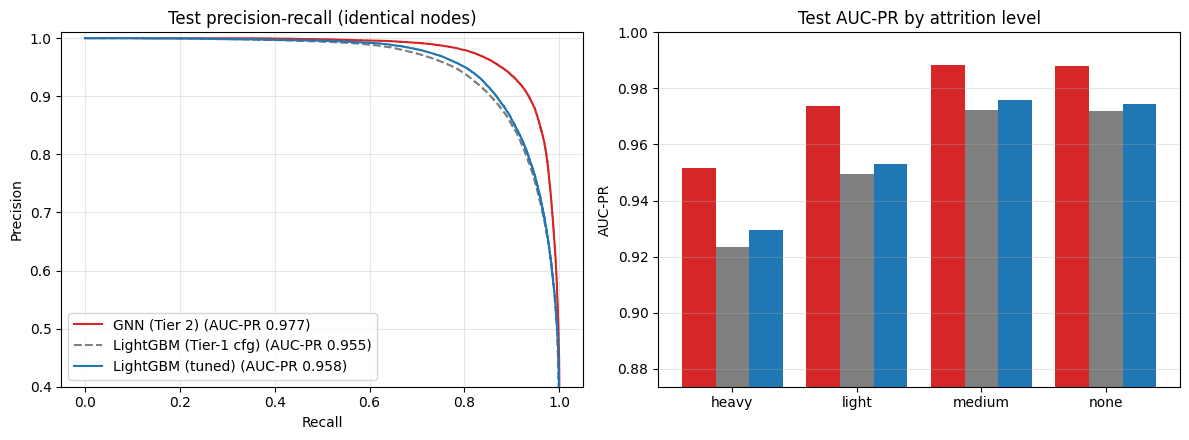

Saved everything to /content/drive/MyDrive/AE5510/compare_outputs


In [14]:
import matplotlib
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
styles = {"GNN (Tier 2)": ("tab:red", "-"), "LightGBM (Tier-1 cfg)": ("tab:gray", "--"), "LightGBM (tuned)": ("tab:blue", "-")}
for n, (pv, pt) in MODELS.items():
    pr, rc, th = precision_recall_curve(y_te, pt)
    c, ls = styles[n]
    ax[0].plot(rc, pr, color=c, ls=ls, label=f"{n} (AUC-PR {average_precision_score(y_te, pt):.3f})")
ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision"); ax[0].set_title("Test precision-recall (identical nodes)")
ax[0].set_ylim(0.4, 1.01); ax[0].legend(loc="lower left"); ax[0].grid(alpha=.3)

b = bd["attrition"]
w = 0.27
xs = np.arange(len(b))
for i, n in enumerate(names):
    ax[1].bar(xs + (i - 1) * w, b[f"AUCPR {n}"].values, w, color=styles[n][0], label=n)
ax[1].set_xticks(xs); ax[1].set_xticklabels(b.index)
ax[1].set_ylim(max(0.5, np.nanmin(b[[f"AUCPR {n}" for n in names]].values) - 0.05), 1.0)
ax[1].set_title("Test AUC-PR by attrition level"); ax[1].set_ylabel("AUC-PR"); ax[1].grid(axis="y", alpha=.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "tier1_vs_tier2_neck_to_neck.png"), dpi=200)
plt.show()

pred_out = m_te[["case_id", "step", "y", "criticality_score"]].copy()
for n, (pv, pt) in MODELS.items():
    pred_out["p_" + n] = pt
pred_out.to_csv(os.path.join(OUT_DIR, "test_predictions_all_models.csv"), index=False)
m_t1.booster_.save_model(os.path.join(OUT_DIR, "lightgbm_tier1_cfg.txt"))
json.dump({"tuned_config": best_cfg_lgb, "thresholds": THR}, open(os.path.join(OUT_DIR, "config_and_thresholds.json"), "w"), indent=2, default=float)
print("Saved everything to", OUT_DIR)

## How to read this
1. Check the **sanity line** in section 6 first - it must say "GNN reproduces the deck numbers".
2. **Section 8** answers "is the GNN's AUC-PR advantage real?" (CI of the difference excludes 0 = yes).
3. **Section 9** gives equal-precision / equal-recall comparisons; **section 7** gives each model at its own validation-chosen thresholds.
4. Sections 10-12 are the robustness story. If a gap is small and the groups have few scenarios, present it as indicative.
5. The only thing LightGBM lacks is the graph edges. Whatever gap remains is the value of message passing.